In [9]:
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
import cv2
from PIL import Image

import tensorflow as tf 
from tensorflow import keras 
from keras.datasets import mnist
from tensorflow.math import confusion_matrix

In [2]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
(X_train , Y_train) , (X_test , Y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [11]:
X_train

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [33]:
X_train[1]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  51, 159, 253, 159,  50,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  48, 238, 252, 252, 252, 237,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [12]:
X_train.shape

(60000, 28, 28)

##### We have 60000 image with dimension of 28 x 28

In [13]:
Y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

In [14]:
Y_train.shape

(60000,)

In [15]:
X_test.shape

(10000, 28, 28)

#### Information we have of dataset 

#####  The training data contain 60000 images  The test data contain 10000 images
##### Image dimension with 28 x 28  Image is grey as there is no dimension after  28 , 28   (greyscale have 1 but not shown like 28,28,1 would still be greyscale image )   for ex if it was 60000,28,28,3.The  3 tell us it rgb images 

__________________________________________________________________________

##### Checking the data

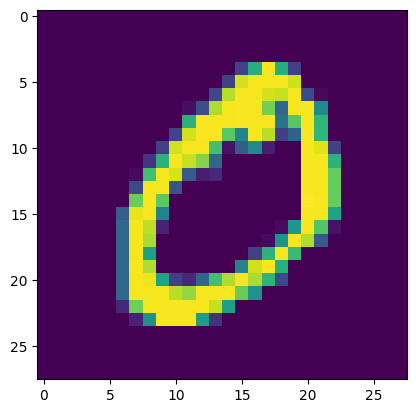

In [17]:
plt.imshow(X_train[1])



In [18]:
# The output of this is 

print(Y_train[1])

0


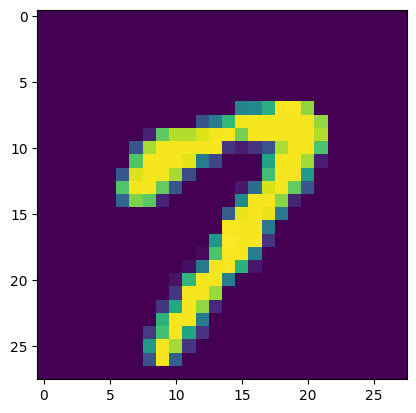

In [31]:
plt.imshow(X_train[15])

In [32]:
print(Y_train[15])

7


Normalization

converting the value of image that can be from 0-255 
to 0-1 as large image can make training the model difficult "

In [35]:
X_train_scaled=X_train/255
X_test_scaled=X_test/255

In [39]:
X_train[10][4]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  42, 118,
       219, 166, 118, 118,   6,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=uint8)

In [40]:
X_train_scaled[10][4]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.16470588, 0.4627451 , 0.85882353, 0.65098039,
       0.4627451 , 0.4627451 , 0.02352941, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        ])

In [ ]:
model=keras.Sequential([
         keras.layers.Flatten(input_shape=(28,28)),
         keras.layers.Dense(50, activation='relu' ),
         keras.layers.Dense( 50,activation='relu'),
         keras.layers.Dense(10 ,activation='sigmoid'),



])